# UniFault Foundation Model을 활용한 미세결함 Few-shot 분류 실습
## 미세결함 미학습 조건 vs 미세결함 Few-shot 학습 조건 비교

> **실습 방법:** Google Colab에서 이 노트북을 열고 **위에서부터 셀을 순서대로 실행**합니다.  
> UniFault 코드, 사전학습 가중치, 실습 데이터가 자동으로 준비됩니다.

이번 실습의 최종 Classification Head는 두 실험 모두 동일하게 **4개 상태**만 분류합니다.

```text
Normal / Imbalance / Inner / Outer
```

원 데이터에는 결함 크기가 여러 단계로 존재하지만 최종 label은 다음과 같이 통합합니다.

- Imbalance 1.8g / 3.6g / 5.4g → **Imbalance**
- Inner 1.0mm + MicroInner 0.15 / 0.4 / 0.7mm → **Inner**
- Outer 1.5mm + MicroOuter 0.2 / 0.6 / 1.0mm → **Outer**

### 비교할 두 조건

**① 미세결함 미학습**
- Normal, Imbalance, 일반 Inner 1.0mm, 일반 Outer 1.5mm만 학습
- 미세 Inner / Outer 데이터는 학습에 사용하지 않음
- 미세결함 시험 데이터가 들어왔을 때 Inner / Outer로 얼마나 분류하는지 확인

**② 미세결함 Few-shot 학습**
- 기존 학습 데이터는 그대로 유지
- 각 미세결함 크기 조건에서 측정 데이터 1개만 추가
- MicroInner는 **Inner**, MicroOuter는 **Outer** label로 학습

두 조건 모두 **동일한 시험 데이터와 동일한 4-class Head**를 사용합니다.  
따라서 미세결함 소량 학습 전후의 성능 차이를 직접 비교할 수 있습니다.


## 0. Colab GPU 사용 설정

Colab 상단 메뉴에서  
`런타임 → 런타임 유형 변경 → 하드웨어 가속기 → GPU`를 선택합니다.

아래 셀은 GPU 연결 상태를 확인합니다.

In [ ]:
import torch

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
else:
    print("GPU가 연결되지 않았습니다. Colab 런타임 설정을 확인하세요.")

PyTorch version : 2.14.1+cpu
CUDA available  : False
GPU가 연결되지 않았습니다. Colab 런타임 설정을 확인하세요.


## 1. UniFault 공식 코드 설치

아래 셀은 UniFault 공식 GitHub 저장소를 Colab으로 가져옵니다.

**수정할 부분 없음. 그대로 실행합니다.**

In [ ]:
# ============================================================
# UniFault 공식 코드 다운로드
# ============================================================

import os

# 먼저 안전한 위치로 이동
os.chdir("/content")

# 기존 UniFault 폴더가 있으면 삭제
!rm -rf /content/UniFault

# UniFault 공식 GitHub 코드 다운로드
!git clone https://github.com/emadeldeen24/UniFault.git /content/UniFault

# UniFault 폴더로 이동
os.chdir("/content/UniFault")

print("현재 작업 위치:", os.getcwd())
print("UniFault 코드 다운로드 완료!")

Cloning into '/content/UniFault'...
remote: Enumerating objects: 24, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 24 (delta 4), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (24/24), 19.06 KiB | 1.47 MiB/s, done.
Resolving deltas: 100% (4/4), done.
현재 작업 위치: /content/UniFault
UniFault 코드 다운로드 완료!


## 2. 필요한 라이브러리 설치

UniFault 모델과 이번 실습에 필요한 라이브러리를 설치합니다.

**수정할 부분 없음. 그대로 실행합니다.**

In [ ]:
import os

# pip 실행 전에 UniFault 폴더가 존재하는지 확인
os.chdir("/content/UniFault")

!pip -q install pytorch-lightning torchmetrics timm einops scipy scikit-learn pandas matplotlib seaborn gdown

print("필요 라이브러리 설치 완료!")

필요 라이브러리 설치 완료!


## 3. 라이브러리 불러오기

In [ ]:
import os
import re
import json
import random
import shutil
import zipfile
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from model.model import Transformer_bkbone

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", DEVICE)

사용 장치: cpu


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


## 4. UniFault Tiny 사전학습 가중치 자동 다운로드

UniFault는 모델 구조만으로 동작하는 것이 아니라, **사전학습된 가중치(checkpoint)** 가 필요합니다.

아래 셀은 UniFault 공식 README에 연결된 Tiny Model 다운로드 경로에서 사전학습 파일을 자동으로 내려받아
`/content/UniFault/pretrained_models/Tiny/` 폴더에 준비합니다.

**수정할 부분 없음. 그대로 실행합니다.**


In [ ]:
# ============================================================
# UniFault Tiny 사전학습 가중치 자동 다운로드
# ============================================================

import requests
import zipfile
import shutil
from pathlib import Path

# UniFault 공식 README의 Tiny Model Download Link가 연결되는 Dropbox 공유 폴더
TINY_MODEL_URL = (
    "https://www.dropbox.com/scl/fo/kolaib1t6o2q96b7qxbsn/"
    "AFEUxkRP54i3xg6OsOQzhJ4"
    "?rlkey=ve3mt6w9tfbi5khkn8s8eqvwt&st=3aol1fey&dl=1"
)

DOWNLOAD_PATH = Path("/content/unifault_tiny_model.zip")
EXTRACT_DIR = Path("/content/unifault_tiny_model")
CKPT_DIR = Path("/content/UniFault/pretrained_models/Tiny")
CKPT_PATH = CKPT_DIR / "pretrain-epoch=1.ckpt"

CKPT_DIR.mkdir(parents=True, exist_ok=True)

# 이미 준비되어 있으면 다시 받지 않음
if CKPT_PATH.exists():
    print("사전학습 가중치가 이미 준비되어 있습니다.")
    print("Checkpoint:", CKPT_PATH)

else:
    print("UniFault Tiny 사전학습 가중치를 다운로드합니다.")

    response = requests.get(TINY_MODEL_URL, stream=True, timeout=120)
    response.raise_for_status()

    with open(DOWNLOAD_PATH, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    # Dropbox 공유 폴더는 ZIP 형태로 다운로드됨
    if not zipfile.is_zipfile(DOWNLOAD_PATH):
        raise RuntimeError(
            "사전학습 파일 다운로드 형식을 확인할 수 없습니다.\n"
            "UniFault 공식 README의 Tiny Model Download Link가 변경되었을 수 있습니다."
        )

    if EXTRACT_DIR.exists():
        shutil.rmtree(EXTRACT_DIR)

    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(DOWNLOAD_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)

    # 압축 내부에서 원하는 checkpoint 자동 탐색
    candidates = list(EXTRACT_DIR.rglob("pretrain-epoch=1.ckpt"))

    if len(candidates) == 0:
        # 이름이 조금 달라진 경우 .ckpt 파일 전체 탐색
        candidates = list(EXTRACT_DIR.rglob("*.ckpt"))

    if len(candidates) == 0:
        raise FileNotFoundError("다운로드한 Tiny Model 폴더에서 .ckpt 파일을 찾지 못했습니다.")

    shutil.copy2(candidates[0], CKPT_PATH)

    print("사전학습 가중치 준비 완료!")
    print("Checkpoint:", CKPT_PATH)
    print("파일 크기(MB):", round(CKPT_PATH.stat().st_size / (1024**2), 2))


UniFault Tiny 사전학습 가중치를 다운로드합니다.
사전학습 가중치 준비 완료!
Checkpoint: /content/UniFault/pretrained_models/Tiny/pretrain-epoch=1.ckpt
파일 크기(MB): 9.38


## 5. 회전체 실험 데이터 다운로드

실습에 사용할 회전체 진동 데이터는 **Google Drive 공유 링크**에 미리 준비되어 있습니다.

아래 셀을 실행하면 ZIP 파일을 Colab으로 자동 다운로드한 뒤 압축을 해제합니다.  
따라서 실습자가 별도로 데이터 파일을 업로드할 필요는 없습니다.

압축 해제가 완료되면 `.mat` 파일의 개수와 예시 파일 경로를 출력하여 데이터가 정상적으로 준비되었는지 확인합니다.


In [ ]:
# ============================================================
# 회전체 실험 데이터 자동 다운로드 및 압축 해제
# ============================================================

!pip -q install gdown

import gdown
import zipfile
import shutil
from pathlib import Path

# Google Drive 공유 파일 ID
FILE_ID = "1JNooOpVBa8Onu969W1Xgup6_3HxAi80b"

# Colab 내부 저장 경로
ZIP_PATH = Path("/content/회전체_실험_데이터_공개.zip")
DATA_ROOT = Path("/content/rotating_fault_dataset")

# 1. Google Drive에서 ZIP 파일 다운로드
if ZIP_PATH.exists() and zipfile.is_zipfile(ZIP_PATH):
    print("이미 다운로드된 ZIP 파일을 사용합니다.")
else:
    if ZIP_PATH.exists():
        ZIP_PATH.unlink()

    print("회전체 실험 데이터 공개를 다운로드합니다.")
    gdown.download(
        id=FILE_ID,
        output=str(ZIP_PATH),
        quiet=False
    )

# 2. 정상적인 ZIP 파일인지 확인
if not ZIP_PATH.exists() or not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(
        "데이터 다운로드에 실패했거나 정상적인 ZIP 파일이 아닙니다. "
        "Google Drive 공유 권한이 '링크가 있는 모든 사용자 - 뷰어'인지 확인하세요."
    )

# 3. 기존 압축 해제 폴더 초기화
if DATA_ROOT.exists():
    shutil.rmtree(DATA_ROOT)

DATA_ROOT.mkdir(parents=True, exist_ok=True)

# 4. 압축 해제
print("압축을 해제합니다.")
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(DATA_ROOT)

# 5. MAT 파일 확인
mat_files = list(DATA_ROOT.rglob("*.mat"))

print("\n데이터 준비 완료!")
print("데이터 위치:", DATA_ROOT)
print("MAT 파일 수:", len(mat_files))

if len(mat_files) > 0:
    print("예시 파일:", mat_files[0])
else:
    raise FileNotFoundError("압축을 해제했지만 .mat 파일을 찾지 못했습니다.")


회전체 실험 데이터 공개를 다운로드합니다.


Downloading...
From (original): https://drive.google.com/uc?id=1JNooOpVBa8Onu969W1Xgup6_3HxAi80b
From (redirected): https://drive.google.com/uc?id=1JNooOpVBa8Onu969W1Xgup6_3HxAi80b&confirm=t&uuid=1aa42aa0-d558-4fb5-81b5-78a256a0151a
To: /content/회전체_실험_데이터_공개.zip
100%|██████████| 74.1M/74.1M [00:01<00:00, 48.4MB/s]


압축을 해제합니다.

데이터 준비 완료!
데이터 위치: /content/rotating_fault_dataset
MAT 파일 수: 160
예시 파일: /content/rotating_fault_dataset/종합_앞부분3초_정속조건/a_5.4g_4.mat


## 6. 실험 설정

각 결함 크기 조건에는 5개의 독립 측정 데이터가 있습니다.

`TRAIN_POSITION = 1`이면 각 5개 묶음에서:

- 1개 → 학습 후보
- 나머지 4개 → 두 실험이 공통으로 사용하는 시험 데이터

미세결함 미학습 조건에서는 미세결함의 학습 후보를 제외하고,  
Few-shot 조건에서는 그 미세결함 학습 후보를 추가합니다.


In [1]:
# ============================================================
# [사용자 수정 가능 설정]
# ============================================================

MAT_KEY = "a"

# MATLAB a(:,1) = Python a[:, 0]
SIGNAL_COLUMN = 0

WINDOW_SIZE = 2048
STRIDE = 2048

# 각 5개 독립 측정 중 몇 번째를 1-shot 후보로 사용할지 지정
TRAIN_POSITION = 1

BATCH_SIZE = 64
EPOCHS = 50
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
SEED = 42

# UniFault Tiny
PATCH_SIZE = 64
EMBED_DIM = 128
HEADS = 4
DEPTH = 4
DROPOUT = 0.3

print("설정 완료")
print("1-shot 후보 위치:", TRAIN_POSITION)


설정 완료
1-shot 후보 위치: 1


## 7. 원 데이터 상태와 최종 4개 분류 상태

원 데이터의 세부 결함 크기는 데이터 구분을 위해 유지합니다.  
하지만 Classification Head가 출력하는 상태는 다음 **4개뿐**입니다.

| 원 데이터 상태 | 최종 Head label |
|---|---|
| Normal | **Normal** |
| Imbalance 1.8g | **Imbalance** |
| Imbalance 3.6g | **Imbalance** |
| Imbalance 5.4g | **Imbalance** |
| Inner 1.0mm | **Inner** |
| MicroInner 0.15mm | **Inner** |
| MicroInner 0.4mm | **Inner** |
| MicroInner 0.7mm | **Inner** |
| Outer 1.5mm | **Outer** |
| MicroOuter 0.2mm | **Outer** |
| MicroOuter 0.6mm | **Outer** |
| MicroOuter 1.0mm | **Outer** |

즉 미세결함은 새로운 출력 클래스로 만드는 것이 아니라,  
**기존 Inner / Outer 상태에 포함되는 더 작은 결함 데이터**로 사용합니다.


In [ ]:
# ============================================================
# 원 데이터 12개 상태 → 최종 4개 Head label
# ============================================================

RAW_CLASS_NAMES = [
    "Normal",
    "Imbalance_1.8g",
    "Imbalance_3.6g",
    "Imbalance_5.4g",
    "Inner_1.0mm",
    "Outer_1.5mm",
    "MicroInner_0.15mm",
    "MicroInner_0.4mm",
    "MicroInner_0.7mm",
    "MicroOuter_0.2mm",
    "MicroOuter_0.6mm",
    "MicroOuter_1.0mm",
]

# Classification Head의 실제 출력
CLASS_NAMES = [
    "Normal",
    "Imbalance",
    "Inner",
    "Outer",
]

# 원 데이터 상태 -> 4-class Head label
RAW_TO_HEAD = {
    0: 0,   # Normal
    1: 1,   # Imbalance 1.8g
    2: 1,   # Imbalance 3.6g
    3: 1,   # Imbalance 5.4g
    4: 2,   # Inner 1.0mm
    5: 3,   # Outer 1.5mm
    6: 2,   # MicroInner 0.15mm
    7: 2,   # MicroInner 0.4mm
    8: 2,   # MicroInner 0.7mm
    9: 3,   # MicroOuter 0.2mm
    10: 3,  # MicroOuter 0.6mm
    11: 3,  # MicroOuter 1.0mm
}

BASE_RAW_IDS = np.arange(0, 6)
MICRO_RAW_IDS = np.arange(6, 12)
MICRO_INNER_RAW_IDS = np.array([6, 7, 8])
MICRO_OUTER_RAW_IDS = np.array([9, 10, 11])

def infer_raw_class(path: Path):
    s = str(path).lower().replace("\\", "/")

    if "normal" in s:
        return 0

    if "1.8g" in s:
        return 1
    if "3.6g" in s:
        return 2
    if "5.4g" in s:
        return 3

    # 미세결함을 일반 Inner / Outer보다 먼저 구분
    if "inner" in s and ("0.15" in s or "015" in s):
        return 6
    if "inner" in s and ("0.4" in s or "04mm" in s):
        return 7
    if "inner" in s and ("0.7" in s or "07mm" in s):
        return 8

    if "outer" in s and ("0.2" in s or "02mm" in s):
        return 9
    if "outer" in s and ("0.6" in s or "06mm" in s):
        return 10
    if "outer" in s and ("1.0" in s or "10mm" in s):
        return 11

    if "inner" in s:
        return 4
    if "outer" in s:
        return 5

    return None

print("최종 Head 출력:", CLASS_NAMES)
print("출력 클래스 수:", len(CLASS_NAMES))


최종 Head 출력: ['Normal', 'Imbalance', 'Inner', 'Outer']
출력 클래스 수: 4


## 8. 파일 목록 확인

각 `.mat` 파일에서 다음 정보를 정리합니다.

- `raw_class_id`: 원 데이터의 세부 결함 조건
- `class_id`: Classification Head에서 사용할 4개 label
- `is_micro`: 미세결함 여부
- `file_no`: 독립 측정 번호

원 데이터의 세부 결함 크기는 **Few-shot 데이터 선택과 미세결함 성능 분석**에 사용합니다.


In [ ]:
def extract_file_number(path: Path):
    m = re.search(r"_(\d+)\.mat$", path.name.lower())
    if m is None:
        return None
    return int(m.group(1))

records = []

for path in sorted(DATA_ROOT.rglob("*.mat")):
    raw_class_id = infer_raw_class(path)
    file_no = extract_file_number(path)

    if file_no is not None and (11 <= file_no <= 20 or 26 <= file_no <= 35):
        continue

    class_id = (
        RAW_TO_HEAD[raw_class_id]
        if raw_class_id is not None else None
    )

    records.append({
        "path": str(path),
        "file": path.name,
        "raw_class_id": raw_class_id,
        "class_id": class_id,
        "file_no": file_no,
    })

df = pd.DataFrame(records)

df["is_micro"] = df["raw_class_id"].isin(MICRO_RAW_IDS)

print("전체 MAT 파일 수:", len(df))
display(df.head(20))

print("\n원 데이터 상태별 파일 수")
raw_count = (
    df.dropna(subset=["raw_class_id"])
      .assign(raw_class_id=lambda x: x["raw_class_id"].astype(int))
      .groupby("raw_class_id")
      .size()
      .rename("count")
      .to_frame()
)
display(raw_count)

print("\n최종 4-class label별 파일 수")
head_count = (
    df.dropna(subset=["class_id"])
      .assign(class_id=lambda x: x["class_id"].astype(int))
      .groupby("class_id")
      .size()
      .reindex(range(len(CLASS_NAMES)), fill_value=0)
      .rename("count")
      .to_frame()
)
head_count["class_name"] = CLASS_NAMES
display(head_count)

unmatched = df[
    df["raw_class_id"].isna() |
    df["class_id"].isna() |
    df["file_no"].isna()
]

print("\n인식하지 못한 파일 수:", len(unmatched))
display(unmatched.head(30))


전체 MAT 파일 수: 160


,path,file,raw_class_id,class_id,file_no,is_micro
0,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_1.mat,9,3,1,True
1,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_10.mat,9,3,10,True
2,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_2.mat,9,3,2,True
3,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_21.mat,9,3,21,True
4,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_22.mat,9,3,22,True
5,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_23.mat,9,3,23,True
6,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_24.mat,9,3,24,True
7,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_25.mat,9,3,25,True
8,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_3.mat,9,3,3,True
9,/content/rotating_fault_dataset/종합_앞부분3초_정속조건/...,a_0.2_outer_4.mat,9,3,4,True



원 데이터 상태별 파일 수


,count
raw_class_id,
0,15
1,15
2,10
3,15
4,15
5,15
7,15
8,15
9,15



최종 4-class label별 파일 수


,count,class_name
class_id,,
0,15,Normal
1,40,Imbalance
2,45,Inner
3,60,Outer



인식하지 못한 파일 수: 0


,path,file,raw_class_id,class_id,file_no,is_micro


## 9. `.mat` 파일 구조 확인

`.mat` 안의 `a` 배열에서 **첫 번째 열 `a(:,1)`** 을 진동 신호로 사용합니다.

Python에서는 첫 번째 열이 `a[:, 0]`입니다.


In [ ]:
sample_path = Path(df.iloc[0]["path"])
mat = sio.loadmat(sample_path)

print("예시 파일:", sample_path.name)
print("MAT 내부 변수:", [k for k in mat.keys() if not k.startswith("__")])

if MAT_KEY not in mat:
    raise KeyError(f"{sample_path.name} 안에 '{MAT_KEY}' 변수가 없습니다.")

a = np.asarray(mat[MAT_KEY])

print("a shape:", a.shape)

signal = a[:, SIGNAL_COLUMN].astype(np.float32)

print("사용 신호 길이:", len(signal))
print("사용 열 번호(Python):", SIGNAL_COLUMN)


예시 파일: a_0.2_outer_1.mat
MAT 내부 변수: ['a']
a shape: (38400, 3)
사용 신호 길이: 38400
사용 열 번호(Python): 0


## 10. 공통 시험 데이터와 Few-shot 후보 데이터 분리

각 세부 결함 조건의 파일 번호를 5개씩 하나의 묶음으로 봅니다.

```text
1~5
6~10
11~15
...
```

`TRAIN_POSITION = 1`이면 각 묶음에서:

- 첫 번째 측정 → 학습 후보
- 나머지 4개 측정 → 공통 시험 데이터

### 실험 A. 미세결함 미학습
학습 후보 중 다음 데이터만 사용합니다.

```text
Normal
Imbalance 1.8 / 3.6 / 5.4g
Inner 1.0mm
Outer 1.5mm
```

### 실험 B. 미세결함 Few-shot
실험 A의 학습 데이터에 다음 미세결함 후보를 추가합니다.

```text
MicroInner 0.15 / 0.4 / 0.7mm → Inner
MicroOuter 0.2 / 0.6 / 1.0mm → Outer
```

시험 데이터는 두 실험에서 완전히 동일합니다.


In [ ]:
def position_in_group(file_no):
    return ((file_no - 1) % 5) + 1

valid_df = df.dropna(
    subset=["raw_class_id", "class_id", "file_no"]
).copy()

valid_df["raw_class_id"] = valid_df["raw_class_id"].astype(int)
valid_df["class_id"] = valid_df["class_id"].astype(int)
valid_df["file_no"] = valid_df["file_no"].astype(int)

valid_df["group_position"] = valid_df["file_no"].apply(position_in_group)
valid_df["is_micro"] = valid_df["raw_class_id"].isin(MICRO_RAW_IDS)
valid_df["is_shot_candidate"] = (
    valid_df["group_position"] == TRAIN_POSITION
)

# 두 실험이 공유하는 동일 시험 데이터
test_meta = valid_df[
    ~valid_df["is_shot_candidate"]
].reset_index(drop=True)

# 각 세부 결함 조건의 1-shot 후보
shot_meta = valid_df[
    valid_df["is_shot_candidate"]
].reset_index(drop=True)

# A. 미세결함 미학습
# Normal / Imbalance / 일반 Inner / 일반 Outer만 사용
baseline_train_meta = shot_meta[
    ~shot_meta["is_micro"]
].reset_index(drop=True)

# B. 미세결함 Few-shot
# 위 데이터 + 각 미세결함 조건의 1-shot 후보 추가
fewshot_train_meta = shot_meta.copy().reset_index(drop=True)

print("===== 측정 파일 수 =====")
print("A. 미세결함 미학습 Train :", len(baseline_train_meta))
print("B. 미세결함 Few-shot Train:", len(fewshot_train_meta))
print("공통 Test                 :", len(test_meta))

def show_train_summary(meta, title):
    print(f"\n===== {title} =====")

    summary = (
        meta.groupby(["class_id", "is_micro"])
            .size()
            .rename("files")
            .reset_index()
    )

    summary["class_name"] = summary["class_id"].map(
        lambda x: CLASS_NAMES[int(x)]
    )

    display(
        summary[
            ["class_id", "class_name", "is_micro", "files"]
        ]
    )

show_train_summary(
    baseline_train_meta,
    "A. 미세결함 미학습"
)

show_train_summary(
    fewshot_train_meta,
    "B. 미세결함 Few-shot"
)

print("\n===== 공통 Test의 원 세부조건별 파일 수 =====")
test_summary = (
    test_meta.groupby("raw_class_id")
             .size()
             .reindex(range(len(RAW_CLASS_NAMES)), fill_value=0)
             .rename("test_files")
             .to_frame()
)

test_summary["raw_class_name"] = RAW_CLASS_NAMES
display(test_summary)


===== 측정 파일 수 =====
A. 미세결함 미학습 Train : 17
B. 미세결함 Few-shot Train: 32
공통 Test                 : 128

===== A. 미세결함 미학습 =====


,class_id,class_name,is_micro,files
0,0,Normal,False,3
1,1,Imbalance,False,8
2,2,Inner,False,3
3,3,Outer,False,3



===== B. 미세결함 Few-shot =====


,class_id,class_name,is_micro,files
0,0,Normal,False,3
1,1,Imbalance,False,8
2,2,Inner,False,3
3,2,Inner,True,6
4,3,Outer,False,3
5,3,Outer,True,9



===== 공통 Test의 원 세부조건별 파일 수 =====


,test_files,raw_class_name
raw_class_id,,
0,12,Normal
1,12,Imbalance_1.8g
2,8,Imbalance_3.6g
3,12,Imbalance_5.4g
4,12,Inner_1.0mm
5,12,Outer_1.5mm
6,0,MicroInner_0.15mm
7,12,MicroInner_0.4mm
8,12,MicroInner_0.7mm


## 11. 2048-point 윈도우 생성 및 Z-score 정규화

각 독립 측정의 진동 신호를 2048 point씩 나눕니다.

Head 학습에 사용하는 label은 **4개 상태 label**입니다.

```text
Normal / Imbalance / Inner / Outer
```

단, 미세결함 성능을 따로 계산하기 위해 각 윈도우가 원래 어떤 세부 결함 조건에서 왔는지에 대한 `raw_class_id`도 함께 보관합니다.


In [ ]:
EPS = 1e-8

def load_signal(path):
    mat = sio.loadmat(path)

    if MAT_KEY not in mat:
        raise KeyError(f"{path} 안에 '{MAT_KEY}' 변수가 없습니다.")

    a = np.asarray(mat[MAT_KEY])

    if a.ndim != 2:
        raise ValueError(f"예상과 다른 shape: {a.shape}")

    return a[:, SIGNAL_COLUMN].astype(np.float32)

def make_windows(signal, window_size=WINDOW_SIZE, stride=STRIDE):
    windows = []

    for start in range(0, len(signal) - window_size + 1, stride):
        w = signal[start:start + window_size].copy()
        w = (w - w.mean()) / (w.std() + EPS)
        windows.append(w)

    return np.asarray(windows, dtype=np.float32)

def build_window_dataset(meta_df):
    X = []
    y = []
    raw_y = []
    file_uid = []

    for uid, row in meta_df.reset_index(drop=True).iterrows():
        signal = load_signal(row["path"])
        windows = make_windows(signal)

        if len(windows) == 0:
            continue

        X.append(windows[:, None, :])

        # 실제 Head가 학습하는 4-class label
        y.append(
            np.full(
                len(windows),
                int(row["class_id"]),
                dtype=np.int64
            )
        )

        # 미세결함 여부/크기 분석을 위한 원 label
        raw_y.append(
            np.full(
                len(windows),
                int(row["raw_class_id"]),
                dtype=np.int64
            )
        )

        file_uid.extend([uid] * len(windows))

    if len(X) == 0:
        raise ValueError("윈도우를 생성할 수 있는 데이터가 없습니다.")

    X = np.concatenate(X, axis=0)
    y = np.concatenate(y, axis=0)
    raw_y = np.concatenate(raw_y, axis=0)
    file_uid = np.asarray(file_uid, dtype=np.int64)

    return X, y, raw_y, file_uid

# 모든 1-shot 후보
shot_X, shot_y, shot_raw_y, shot_uid = build_window_dataset(
    fewshot_train_meta
)

# 두 실험의 공통 시험 데이터
test_X, test_y, test_raw_y, test_uid = build_window_dataset(
    test_meta
)

print("1-shot 후보 X:", shot_X.shape)
print("1-shot 후보 Head label:", shot_y.shape)
print("공통 Test X:", test_X.shape)
print("공통 Test Head label:", test_y.shape)

print("\nHead label 종류:", np.unique(test_y))
print("원 세부조건 종류:", np.unique(test_raw_y))


1-shot 후보 X: (576, 1, 2048)
1-shot 후보 Head label: (576,)
공통 Test X: (2304, 1, 2048)
공통 Test Head label: (2304,)

Head label 종류: [0 1 2 3]
원 세부조건 종류: [ 0  1  2  3  4  5  7  8  9 10 11]


## 12. Batch 단위로 UniFault Backbone에 입력

Backbone에는 진동 윈도우를 입력하고,  
평가 단계에서 미세결함 데이터만 따로 분리할 수 있도록 `raw_class_id`도 함께 전달합니다.


In [ ]:
class WindowDataset(Dataset):
    def __init__(self, X, y, raw_y, uid):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()
        self.raw_y = torch.from_numpy(raw_y).long()
        self.uid = torch.from_numpy(uid).long()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            self.y[idx],
            self.raw_y[idx],
            self.uid[idx]
        )

shot_ds = WindowDataset(
    shot_X,
    shot_y,
    shot_raw_y,
    shot_uid
)

test_ds = WindowDataset(
    test_X,
    test_y,
    test_raw_y,
    test_uid
)

shot_loader = DataLoader(
    shot_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

print("1-shot 후보 batches:", len(shot_loader))
print("공통 Test batches   :", len(test_loader))


1-shot 후보 batches: 9
공통 Test batches   : 36


## 13. UniFault Tiny Backbone 구성

UniFault Tiny 설정:

- Embedding dimension: 128
- Attention heads: 4
- Transformer depth: 4
- Patch size: 64

2048-point 윈도우를 64 point씩 나누므로 한 윈도우에서 32개의 patch가 만들어집니다.


In [ ]:
args = SimpleNamespace(
    seq_len=WINDOW_SIZE,
    patch_size=PATCH_SIZE,
    embed_dim=EMBED_DIM,
    heads=HEADS,
    depth=DEPTH,
    dropout=DROPOUT,
    num_channels=1,
    num_classes=16,
)

backbone = Transformer_bkbone(args)

print("UniFault Tiny 생성 완료")
print("Patch 개수:", backbone.patch_embed.num_patches)


UniFault Tiny 생성 완료
Patch 개수: 32


## 14. 사전학습 UniFault 가중치 불러오기

UniFault Tiny의 사전학습 Backbone 가중치를 불러옵니다.

이번 실습은 2048-point 윈도우를 사용하므로,  
사전학습 checkpoint의 positional embedding 길이가 다르면 현재 patch 수에 맞춰 보간합니다.

이후 Backbone은 **Frozen** 상태로 유지합니다.


In [ ]:
def clean_key(k):
    prefixes = ["model.model.", "model.", "backbone."]

    for prefix in prefixes:
        if k.startswith(prefix):
            return k[len(prefix):]

    return k

checkpoint = torch.load(CKPT_PATH, map_location="cpu")

raw_state = checkpoint["state_dict"] if "state_dict" in checkpoint else checkpoint
clean_state = {clean_key(k): v for k, v in raw_state.items()}

if "pos_embed" in clean_state:
    old_pos = clean_state["pos_embed"]
    new_pos = backbone.pos_embed

    if old_pos.shape != new_pos.shape:
        print("pos_embed 길이 보정")
        print("pretrained:", tuple(old_pos.shape))
        print("current   :", tuple(new_pos.shape))

        old_pos = old_pos.permute(0, 2, 1)

        old_pos = F.interpolate(
            old_pos,
            size=new_pos.shape[1],
            mode="linear",
            align_corners=False
        )

        clean_state["pos_embed"] = old_pos.permute(0, 2, 1)

current_state = backbone.state_dict()
matched = {}

for k, v in clean_state.items():
    if k in current_state and current_state[k].shape == v.shape:
        matched[k] = v

backbone.load_state_dict(matched, strict=False)

# Backbone 전체 고정
for param in backbone.parameters():
    param.requires_grad = False

backbone = backbone.to(DEVICE)
backbone.eval()

print("불러온 pretrained parameter 수:", len(matched))
print("Backbone Frozen 완료")


pos_embed 길이 보정
pretrained: (1, 16, 128)
current   : (1, 32, 128)
불러온 pretrained parameter 수: 83
Backbone Frozen 완료


## 15. Frozen Backbone으로 출력 임베딩 추출

UniFault Backbone은 두 실험에서 동일하게 고정합니다.

Backbone 출력이 `[Batch, Patch, 128]` 형태이면 Patch 방향으로 평균하여  
**윈도우 하나당 128차원 임베딩**을 만듭니다.

그 다음:

- A: 일반 결함 데이터의 임베딩만 Head 학습
- B: 같은 데이터 + 미세결함 Few-shot 임베딩 추가

두 실험의 Head 출력은 모두 **4개 상태**입니다.


In [ ]:
def extract_embeddings(model, loader):
    features_all = []
    y_all = []
    raw_y_all = []
    uid_all = []

    model.eval()

    with torch.no_grad():
        for x, y, raw_y, uid in loader:
            x = x.to(DEVICE)

            features = model(x)

            # [B, Patch, 128] -> [B, 128]
            if features.ndim == 3:
                features = features.mean(dim=1)

            if features.ndim != 2:
                raise RuntimeError(
                    f"예상하지 못한 Backbone 출력 shape: "
                    f"{tuple(features.shape)}"
                )

            features_all.append(features.cpu().numpy())
            y_all.append(y.numpy())
            raw_y_all.append(raw_y.numpy())
            uid_all.append(uid.numpy())

    return (
        np.concatenate(features_all, axis=0),
        np.concatenate(y_all, axis=0),
        np.concatenate(raw_y_all, axis=0),
        np.concatenate(uid_all, axis=0)
    )

shot_features, shot_labels, shot_raw_labels, shot_feature_uid = (
    extract_embeddings(backbone, shot_loader)
)

test_features, test_labels, test_raw_labels, test_feature_uid = (
    extract_embeddings(backbone, test_loader)
)

print("1-shot 후보 임베딩:", shot_features.shape)
print("공통 Test 임베딩 :", test_features.shape)

assert shot_features.ndim == 2
assert test_features.ndim == 2
assert shot_features.shape[1] == EMBED_DIM
assert test_features.shape[1] == EMBED_DIM

# A. 원 세부조건 0~5만 사용
baseline_mask = np.isin(
    shot_raw_labels,
    BASE_RAW_IDS
)

baseline_features = shot_features[baseline_mask]
baseline_labels = shot_labels[baseline_mask]

# B. 일반 결함 + 미세결함 Few-shot 전체 사용
fewshot_features = shot_features
fewshot_labels = shot_labels

print("\nA. 미세결함 미학습")
print("학습 윈도우:", len(baseline_labels))
print("Head label:", np.unique(baseline_labels))

print("\nB. 미세결함 Few-shot")
print("학습 윈도우:", len(fewshot_labels))
print("Head label:", np.unique(fewshot_labels))

print("\n최종 Head 출력 클래스:")
for i, name in enumerate(CLASS_NAMES):
    print(i, ":", name)


1-shot 후보 임베딩: (576, 128)
공통 Test 임베딩 : (2304, 128)

A. 미세결함 미학습
학습 윈도우: 306
Head label: [0 1 2 3]

B. 미세결함 Few-shot
학습 윈도우: 576
Head label: [0 1 2 3]

최종 Head 출력 클래스:
0 : Normal
1 : Imbalance
2 : Inner
3 : Outer


## 16. 동일한 4-class Classification Head 학습

두 실험의 Head 구조는 완전히 동일합니다.

```text
128D Embedding
      ↓
Linear Head
      ↓
Normal / Imbalance / Inner / Outer
```

### A. 미세결함 미학습
- 일반 Inner / Outer 결함은 학습
- 미세 Inner / Outer는 학습하지 않음

### B. 미세결함 Few-shot
- A와 동일한 학습 데이터
- 각 미세결함 크기 조건의 측정 데이터 1개씩만 추가
- MicroInner → Inner
- MicroOuter → Outer

공정한 비교를 위해 두 Head는 같은 random seed로 초기화합니다.


In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class EmbeddingDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.from_numpy(features).float()
        self.labels = torch.from_numpy(labels).long()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]

def train_head(features, labels, experiment_name):
    # 두 조건의 Head를 동일하게 초기화
    set_seed(SEED)

    ds = EmbeddingDataset(features, labels)

    g = torch.Generator()
    g.manual_seed(SEED)

    loader = DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=g,
        drop_last=False
    )

    head = nn.Linear(EMBED_DIM, len(CLASS_NAMES)).to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        head.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    history = {"loss": [], "acc": []}

    print(f"\n===== {experiment_name} =====")

    for epoch in range(1, EPOCHS + 1):
        head.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for feat, y in loader:
            feat = feat.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()

            logits = head(feat)
            loss = criterion(logits, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * y.size(0)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

        epoch_loss = total_loss / total
        epoch_acc = correct / total

        history["loss"].append(epoch_loss)
        history["acc"].append(epoch_acc)

        if epoch == 1 or epoch % 10 == 0 or epoch == EPOCHS:
            print(
                f"Epoch {epoch:3d}/{EPOCHS} | "
                f"Loss {epoch_loss:.4f} | "
                f"Train Acc {epoch_acc*100:.2f}%"
            )

    return head, history

baseline_head, baseline_history = train_head(
    baseline_features,
    baseline_labels,
    "A. 미세결함 미학습"
)

fewshot_head, fewshot_history = train_head(
    fewshot_features,
    fewshot_labels,
    "B. 미세결함 Few-shot"
)



===== A. 미세결함 미학습 =====
Epoch   1/50 | Loss 1.2461 | Train Acc 55.56%
Epoch  10/50 | Loss 0.7284 | Train Acc 81.70%
Epoch  20/50 | Loss 0.4547 | Train Acc 96.08%
Epoch  30/50 | Loss 0.3152 | Train Acc 97.71%
Epoch  40/50 | Loss 0.2339 | Train Acc 99.67%
Epoch  50/50 | Loss 0.1817 | Train Acc 100.00%

===== B. 미세결함 Few-shot =====
Epoch   1/50 | Loss 1.4733 | Train Acc 36.81%
Epoch  10/50 | Loss 0.8627 | Train Acc 69.97%
Epoch  20/50 | Loss 0.6241 | Train Acc 80.21%
Epoch  30/50 | Loss 0.5023 | Train Acc 84.72%
Epoch  40/50 | Loss 0.4281 | Train Acc 86.63%
Epoch  50/50 | Loss 0.3780 | Train Acc 88.19%


## 17. 학습 과정 확인

두 Head의 학습 Loss와 Accuracy를 확인합니다.

여기서 중요한 결과는 학습 정확도 자체보다,  
**동일한 공통 시험 데이터에서 미세결함 분류성능이 얼마나 달라지는지**입니다.


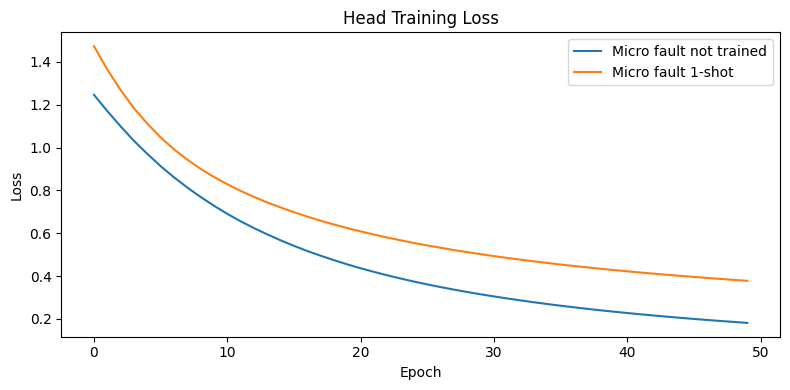

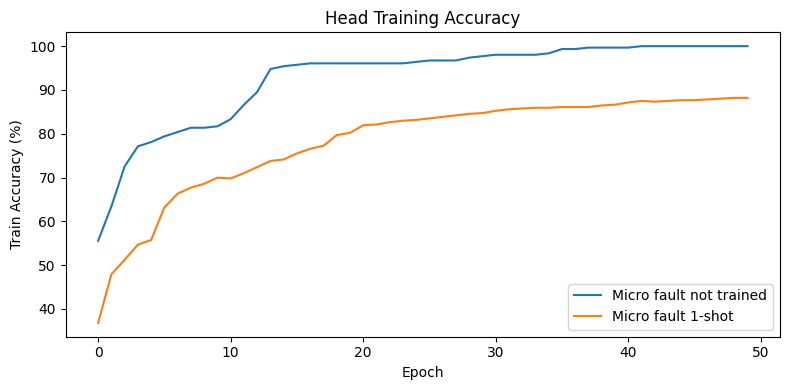

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(baseline_history["loss"], label="Micro fault not trained")
plt.plot(fewshot_history["loss"], label="Micro fault 1-shot")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Head Training Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(np.asarray(baseline_history["acc"]) * 100, label="Micro fault not trained")
plt.plot(np.asarray(fewshot_history["acc"]) * 100, label="Micro fault 1-shot")
plt.xlabel("Epoch")
plt.ylabel("Train Accuracy (%)")
plt.title("Head Training Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


## 18. 공통 시험 데이터에서 Window-level 평가

두 Head를 **동일한 시험 임베딩**에 적용합니다.

평가는 다음을 함께 확인합니다.

- 전체 4-class Accuracy / Macro-F1
- 일반 데이터 Accuracy
- **미세결함 데이터만 따로 분리한 Accuracy / Macro-F1**

미세결함 데이터에서도 정답 label은 새로운 클래스가 아니라  
**Inner 또는 Outer**입니다.


In [ ]:
def predict_probabilities(head, features):
    head.eval()
    probs_all = []

    with torch.no_grad():
        for start in range(0, len(features), BATCH_SIZE):
            feat = torch.from_numpy(
                features[start:start+BATCH_SIZE]
            ).float().to(DEVICE)

            logits = head(feat)
            probs = torch.softmax(logits, dim=1)
            probs_all.append(probs.cpu().numpy())

    return np.concatenate(probs_all, axis=0)

baseline_window_probs = predict_probabilities(
    baseline_head,
    test_features
)

fewshot_window_probs = predict_probabilities(
    fewshot_head,
    test_features
)

baseline_window_pred = baseline_window_probs.argmax(axis=1)
fewshot_window_pred = fewshot_window_probs.argmax(axis=1)

def calculate_metrics(y_true, y_pred, raw_y_true):
    micro_mask = np.isin(raw_y_true, MICRO_RAW_IDS)
    base_mask = np.isin(raw_y_true, BASE_RAW_IDS)

    result = {
        "overall_accuracy": accuracy_score(y_true, y_pred),
        "overall_macro_f1": f1_score(
            y_true,
            y_pred,
            labels=np.arange(len(CLASS_NAMES)),
            average="macro",
            zero_division=0
        ),
        "base_accuracy": accuracy_score(
            y_true[base_mask],
            y_pred[base_mask]
        ),
        "micro_accuracy": accuracy_score(
            y_true[micro_mask],
            y_pred[micro_mask]
        ),
        "micro_macro_f1": f1_score(
            y_true[micro_mask],
            y_pred[micro_mask],
            labels=[2, 3],  # Inner / Outer
            average="macro",
            zero_division=0
        )
    }

    return result

baseline_window_metrics = calculate_metrics(
    test_labels,
    baseline_window_pred,
    test_raw_labels
)

fewshot_window_metrics = calculate_metrics(
    test_labels,
    fewshot_window_pred,
    test_raw_labels
)

window_comparison = pd.DataFrame(
    [baseline_window_metrics, fewshot_window_metrics],
    index=["미세결함 미학습", "미세결함 Few-shot"]
)

display((window_comparison * 100).round(2))
print("※ 단위: %")


,overall_accuracy,overall_macro_f1,base_accuracy,micro_accuracy,micro_macro_f1
미세결함 미학습,69.84,70.09,99.59,36.11,45.14
미세결함 Few-shot,88.15,90.50,97.22,77.87,77.38


※ 단위: %


## 19. 측정 데이터 단위 최종 평가

한 측정 데이터에서 나온 여러 윈도우의 예측 확률을 평균한 뒤  
가장 높은 확률의 상태를 해당 측정 데이터의 최종 분류 결과로 사용합니다.

최종 출력은 항상 다음 4개 중 하나입니다.

```text
Normal / Imbalance / Inner / Outer
```

원 세부조건은 미세결함 성능을 따로 계산하기 위한 분석 정보로만 사용합니다.


In [ ]:
def aggregate_file_predictions(
    window_probs,
    window_y,
    window_raw_y,
    window_uid
):
    file_true = []
    file_raw_true = []
    file_pred = []
    file_prob = []
    file_uid_out = []

    for uid in np.unique(window_uid):
        mask = window_uid == uid

        probs = window_probs[mask]
        labels = window_y[mask]
        raw_labels = window_raw_y[mask]

        assert len(np.unique(labels)) == 1
        assert len(np.unique(raw_labels)) == 1

        mean_prob = probs.mean(axis=0)

        file_uid_out.append(uid)
        file_true.append(labels[0])
        file_raw_true.append(raw_labels[0])
        file_pred.append(mean_prob.argmax())
        file_prob.append(mean_prob)

    return (
        np.asarray(file_true),
        np.asarray(file_raw_true),
        np.asarray(file_pred),
        np.asarray(file_prob),
        np.asarray(file_uid_out)
    )

(
    baseline_file_true,
    baseline_file_raw_true,
    baseline_file_pred,
    baseline_file_prob,
    baseline_file_uid
) = aggregate_file_predictions(
    baseline_window_probs,
    test_labels,
    test_raw_labels,
    test_feature_uid
)

(
    fewshot_file_true,
    fewshot_file_raw_true,
    fewshot_file_pred,
    fewshot_file_prob,
    fewshot_file_uid
) = aggregate_file_predictions(
    fewshot_window_probs,
    test_labels,
    test_raw_labels,
    test_feature_uid
)

assert np.array_equal(
    baseline_file_true,
    fewshot_file_true
)

assert np.array_equal(
    baseline_file_raw_true,
    fewshot_file_raw_true
)

assert np.array_equal(
    baseline_file_uid,
    fewshot_file_uid
)

file_true = baseline_file_true
file_raw_true = baseline_file_raw_true
file_uid = baseline_file_uid

baseline_file_metrics = calculate_metrics(
    file_true,
    baseline_file_pred,
    file_raw_true
)

fewshot_file_metrics = calculate_metrics(
    file_true,
    fewshot_file_pred,
    file_raw_true
)

file_comparison = pd.DataFrame(
    [baseline_file_metrics, fewshot_file_metrics],
    index=["미세결함 미학습", "미세결함 Few-shot"]
)

display((file_comparison * 100).round(2))
print("※ 단위: %")


,overall_accuracy,overall_macro_f1,base_accuracy,micro_accuracy,micro_macro_f1
미세결함 미학습,68.75,69.38,100.0,33.33,41.43
미세결함 Few-shot,89.84,92.17,100.0,78.33,77.83


※ 단위: %


## 20. 핵심 결과: 미세결함 Few-shot 적용 전후 비교

이번 실습에서 가장 중요한 결과입니다.

미세결함 시험 데이터만 따로 분리하여:

- 전체 미세결함 Accuracy
- 미세결함 Inner / Outer Macro-F1

이 Few-shot 적용 전후 어떻게 달라지는지 비교합니다.


,미세결함 Accuracy,미세결함 Macro-F1
미세결함 미학습,33.33,41.43
미세결함 Few-shot,78.33,77.83


/tmp/ipykernel_388/1545372596.py:30: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_388/1545372596.py:30: UserWarning: Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_388/1545372596.py:30: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_388/1545372596.py:30: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_388/1545372596.py:30: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_388/1545372596.py:30: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s

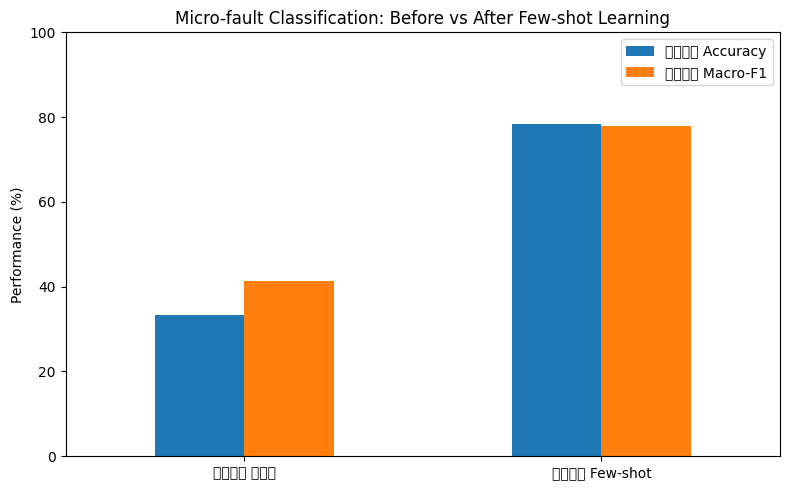

In [ ]:
key_comparison = pd.DataFrame({
    "미세결함 Accuracy": [
        baseline_file_metrics["micro_accuracy"],
        fewshot_file_metrics["micro_accuracy"]
    ],
    "미세결함 Macro-F1": [
        baseline_file_metrics["micro_macro_f1"],
        fewshot_file_metrics["micro_macro_f1"]
    ]
}, index=["미세결함 미학습", "미세결함 Few-shot"])

display((key_comparison * 100).round(2))

ax = (key_comparison * 100).plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_ylabel("Performance (%)")
ax.set_title(
    "Micro-fault Classification: "
    "Before vs After Few-shot Learning"
)
ax.set_ylim(0, 100)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0
)

plt.tight_layout()
plt.show()


## 21. 미세 Inner / Outer 성능을 각각 비교

미세결함을 한꺼번에 보지 않고 다음 두 그룹을 따로 확인합니다.

- **MicroInner 0.15 / 0.4 / 0.7mm**  
  → 정답은 모두 `Inner`

- **MicroOuter 0.2 / 0.6 / 1.0mm**  
  → 정답은 모두 `Outer`

즉 Few-shot 적용 후 작은 Inner / Outer 결함을 기존 4-class Head가 얼마나 더 잘 분류하게 되었는지 확인합니다.


In [ ]:
micro_group_rows = []

groups = [
    (
        "MicroInner",
        MICRO_INNER_RAW_IDS,
        2  # Inner
    ),
    (
        "MicroOuter",
        MICRO_OUTER_RAW_IDS,
        3  # Outer
    )
]

for group_name, raw_ids, correct_head_id in groups:
    mask = np.isin(file_raw_true, raw_ids)

    baseline_acc = (
        (baseline_file_pred[mask] == correct_head_id).mean()
        if mask.sum() > 0 else np.nan
    )

    fewshot_acc = (
        (fewshot_file_pred[mask] == correct_head_id).mean()
        if mask.sum() > 0 else np.nan
    )

    micro_group_rows.append({
        "미세결함 그룹": group_name,
        "시험 파일 수": int(mask.sum()),
        "정답 Head": CLASS_NAMES[correct_head_id],
        "미세결함 미학습 Accuracy": baseline_acc,
        "미세결함 Few-shot Accuracy": fewshot_acc,
        "향상폭": fewshot_acc - baseline_acc
    })

micro_group_comparison = pd.DataFrame(
    micro_group_rows
)

display(
    micro_group_comparison.style.format({
        "미세결함 미학습 Accuracy": "{:.2%}",
        "미세결함 Few-shot Accuracy": "{:.2%}",
        "향상폭": "{:+.2%}"
    })
)


,미세결함 그룹,시험 파일 수,정답 Head,미세결함 미학습 Accuracy,미세결함 Few-shot Accuracy,향상폭
0,MicroInner,24,Inner,33.33%,79.17%,+45.83%
1,MicroOuter,36,Outer,33.33%,77.78%,+44.44%


## 22. 미세결함 미학습 조건 Confusion Matrix

미세결함 데이터를 학습하지 않은 Head의 전체 4-class 결과입니다.

세로축은 실제 상태, 가로축은 예측 상태입니다.


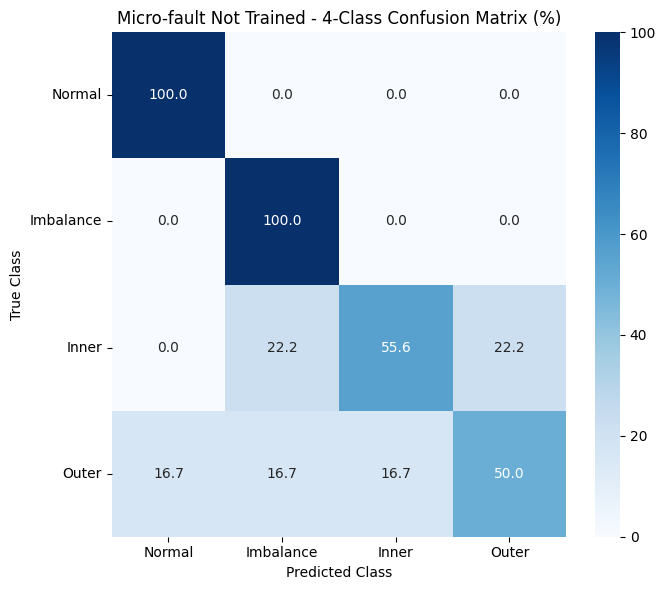

In [ ]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(len(CLASS_NAMES))
    )

    cm_percent = (
        cm /
        np.maximum(cm.sum(axis=1, keepdims=True), 1) *
        100
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm_percent,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        vmin=0,
        vmax=100
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title(title)
    plt.xticks(rotation=0)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

plot_confusion(
    file_true,
    baseline_file_pred,
    "Micro-fault Not Trained - 4-Class Confusion Matrix (%)"
)


## 23. 미세결함 Few-shot 조건 Confusion Matrix

각 미세결함 크기 조건의 측정 데이터 1개씩을 추가 학습한 뒤의  
전체 4-class 결과입니다.

앞의 결과와 비교하여 Inner / Outer 분류가 어떻게 달라지는지 확인합니다.


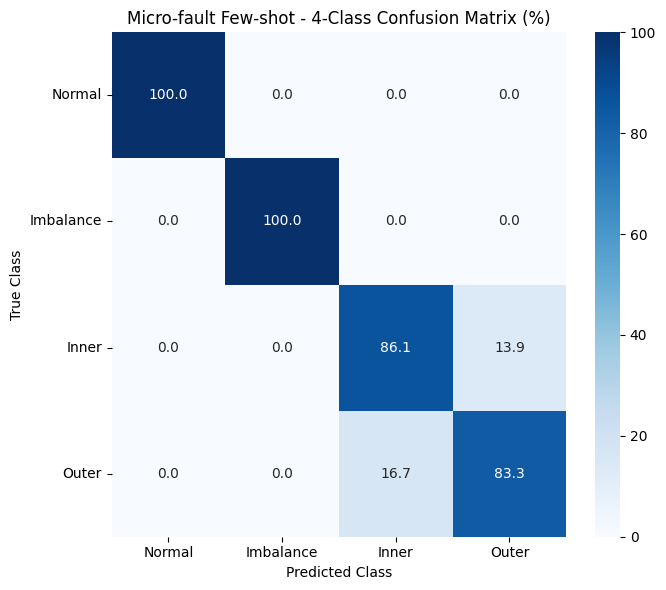

In [ ]:
plot_confusion(
    file_true,
    fewshot_file_pred,
    "Micro-fault Few-shot - 4-Class Confusion Matrix (%)"
)


## 24. 시험 파일별 최종 상태 예측 결과




In [ ]:
print("===== 시험 파일별 최종 예측 결과 (Few-shot) =====\n")

for uid, pred in zip(file_uid, fewshot_file_pred):
    file_name = Path(test_meta.iloc[int(uid)]["file"]).stem
    prediction = CLASS_NAMES[int(pred)]
    print(f"{file_name} → {prediction}")

===== 시험 파일별 최종 예측 결과 (Few-shot) =====

a_0.2_outer_10 → Outer
a_0.2_outer_2 → Inner
a_0.2_outer_22 → Outer
a_0.2_outer_23 → Outer
a_0.2_outer_24 → Outer
a_0.2_outer_25 → Outer
a_0.2_outer_3 → Inner
a_0.2_outer_4 → Inner
a_0.2_outer_5 → Inner
a_0.2_outer_7 → Outer
a_0.2_outer_8 → Outer
a_0.2_outer_9 → Outer
a_0.4_inner_10 → Outer
a_0.4_inner_2 → Outer
a_0.4_inner_22 → Inner
a_0.4_inner_23 → Inner
a_0.4_inner_24 → Inner
a_0.4_inner_25 → Inner
a_0.4_inner_3 → Inner
a_0.4_inner_4 → Inner
a_0.4_inner_5 → Inner
a_0.4_inner_7 → Outer
a_0.4_inner_8 → Outer
a_0.4_inner_9 → Outer
a_0.6_outer_10 → Inner
a_0.6_outer_2 → Outer
a_0.6_outer_22 → Outer
a_0.6_outer_23 → Outer
a_0.6_outer_24 → Outer
a_0.6_outer_25 → Outer
a_0.6_outer_3 → Outer
a_0.6_outer_4 → Outer
a_0.6_outer_5 → Outer
a_0.6_outer_7 → Inner
a_0.6_outer_8 → Inner
a_0.6_outer_9 → Inner
a_0.7_inner_10 → Inner
a_0.7_inner_2 → Inner
a_0.7_inner_22 → Inner
a_0.7_inner_23 → Inner
a_0.7_inner_24 → Inner
a_0.7_inner_25 → Inner
a_0.7_inner_3 → 